# Spatiotemporal Validation and Diagnostic Report: Integration of Meteorological and Air Quality Layers (SIMA–PurpleAir)

In [43]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib import font_manager

FUENTES_SERIF = ["Times New Roman", "Times", "Liberation Serif", "Nimbus Roman", "DejaVu Serif"]
_instaladas = {f.name for f in font_manager.fontManager.ttflist}
if "Times New Roman" not in _instaladas:
    _alterna = next((f for f in FUENTES_SERIF if f in _instaladas), "la serif por defecto")
    print(f"Aviso: Times New Roman no está instalada; se usará {_alterna}.")

COLORES = {"SIMA": "#1F4E79", "PurpleAir": "#7B3FA0", "Diferencia": "#C0392B", "Neutro": "#4D4D4D",
           "PM2.5": "#E69F00", "PM10": "#2E8B57"}

plt.rcParams.update({
    # Tipografía
    "font.family": "serif",
    "font.serif": FUENTES_SERIF,
    "mathtext.fontset": "stix",                # subíndices y µg/m³ con aspecto Times
    "font.size": 16,
    "axes.titlesize": 20, "axes.titleweight": "bold", "axes.titlepad": 14,
    "axes.labelsize": 18, "axes.labelweight": "bold", "axes.labelpad": 8,
    "xtick.labelsize": 15, "ytick.labelsize": 15,
    "legend.fontsize": 14, "legend.title_fontsize": 15,
    "figure.titlesize": 22, "figure.titleweight": "bold",
    # Fondo blanco y sin cuadrícula
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.grid": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "black", "axes.linewidth": 1.2,
    "xtick.major.size": 6, "ytick.major.size": 6,
    "xtick.major.width": 1.2, "ytick.major.width": 1.2,
    # Tamaño y exportación
    "figure.figsize": (14, 6), "figure.dpi": 100,
    "savefig.dpi": 300, "savefig.bbox": "tight",
    # Líneas, marcadores y leyendas
    "lines.linewidth": 2.0, "lines.markersize": 6,
    "legend.frameon": False,
    "axes.prop_cycle": cycler(color=[COLORES["SIMA"], COLORES["PurpleAir"], COLORES["Diferencia"],
                                     "#2E8B57", "#E69F00", "#56B4E9"]),
    # Boxplots
    "boxplot.boxprops.linewidth": 1.5, "boxplot.whiskerprops.linewidth": 1.5,
    "boxplot.capprops.linewidth": 1.5,
    "boxplot.medianprops.color": "black", "boxplot.medianprops.linewidth": 2.2,
    "boxplot.flierprops.marker": "o", "boxplot.flierprops.markersize": 4,
    "boxplot.flierprops.markeredgecolor": COLORES["Neutro"],
})

# Textos en inglés para ejes y títulos
ETIQUETA = {"PM2.5": r"PM$_{2.5}$", "PM10": r"PM$_{10}$"}
EJE_CONC = r"Concentration ($\mu$g/m$^3$)"
EJE_DIF = r"Difference PA $-$ SIMA ($\mu$g/m$^3$)"
# Para gráficas de pastel: ax.pie(valores, labels=..., **ESTILO_PASTEL)
ESTILO_PASTEL = {"wedgeprops": {"edgecolor": "white", "linewidth": 1.5},
                 "textprops": {"fontsize": 15}, "autopct": "%1.1f%%", "startangle": 90}
DIR_FIGURAS = Path("figuras")


def formato_fechas(ax):
    localizador = mdates.AutoDateLocator(minticks=4, maxticks=10)
    ax.xaxis.set_major_locator(localizador)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(localizador))
    ax.set_xlabel("Date")


def guardar(fig, nombre):
    """Guarda la figura en PNG a 300 dpi dentro de la carpeta 'figuras'."""
    DIR_FIGURAS.mkdir(exist_ok=True)
    fig.savefig(DIR_FIGURAS / f"{nombre}.png")

Geographic Coverage Alignment of SIMA and PurpleAir Data for Air Quality

In [44]:
import numpy as np
import pandas as pd
from IPython.display import display

try:
    import geopandas as gpd
except ImportError:
    gpd = None


def encontrar_raiz(inicio=Path.cwd()):
    for carpeta in [inicio, *inicio.parents]:
        if (carpeta / "SIMA").is_dir() and (carpeta / "Purple Air").is_dir():
            return carpeta
    raise FileNotFoundError("No se encontró la raíz del repositorio; asigna RAIZ manualmente.")


RAIZ = encontrar_raiz()
CSV_PURPLEAIR = RAIZ / "Purple Air" / "interpolacion_calidadaire_historico.csv"
CSV_SIMA = RAIZ / "SIMA" / "sima_interpolacion_historico.csv"
ARCHIVO_SHP_AGEB = RAIZ / "shp" / "2025_1_19_A.shp"
CAPA_SENSORES_PA = RAIZ / "Purple Air" / "purpleair_meteo.geojson"
CAPA_ESTACIONES_SIMA = RAIZ / "SIMA" / "sima_meteo.geojson"   # ajustar al archivo de estaciones SIMA

# PurpleAir se registra en UTC (GitHub Actions) y SIMA en hora local (Monterrey, UTC-6).
OFFSET_HORAS = {"PurpleAir": -6, "SIMA": 0}
CONTAMINANTES = ["PM2.5", "PM10"]


def normalizar(df, fuente):
    df = df.copy()
    # Acepta fechas con o sin zona horaria y las redondea a la hora para que ambas redes empaten.
    fechas = pd.to_datetime(df["timestamp"], errors="coerce", utc=True, format="mixed")
    df["timestamp"] = fechas.dt.tz_localize(None).dt.floor("h") + pd.Timedelta(hours=OFFSET_HORAS[fuente])
    df["cvegeo"] = df["cvegeo"].astype(str).str.strip().str.zfill(13)
    for c in CONTAMINANTES:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.dropna(subset=["timestamp"]).dropna(subset=CONTAMINANTES, how="all")
    return df.drop_duplicates(["timestamp", "cvegeo"], keep="last").reset_index(drop=True)


def leer_purpleair(ruta):
    df = pd.read_csv(ruta, encoding="utf-8-sig", dtype={"cvegeo": str}, na_values=["ND"], low_memory=False)
    df = df.rename(columns={"pm25_interpolado": "PM2.5", "pm10_interpolado": "PM10"})
    extras = [c for c in ("metodo", "n_sensores") if c in df.columns]
    return normalizar(df[["timestamp", "cvegeo", *CONTAMINANTES, *extras]], "PurpleAir")


def leer_sima(ruta):
    df = pd.read_csv(ruta, encoding="utf-8-sig", dtype={"CVEGEO": str}, na_values=["ND"], low_memory=False,
                     usecols=["timestamp", "CVEGEO", "PM25_ugm3", "PM10_ugm3"])
    df = df.rename(columns={"CVEGEO": "cvegeo", "PM25_ugm3": "PM2.5", "PM10_ugm3": "PM10"})
    return normalizar(df, "SIMA")


pa_total = leer_purpleair(CSV_PURPLEAIR)
sima_total = leer_sima(CSV_SIMA)

# 1) Cobertura geográfica común
AGEBS_COMUNES = sorted(set(pa_total["cvegeo"]) & set(sima_total["cvegeo"]))
pa = pa_total[pa_total["cvegeo"].isin(AGEBS_COMUNES)]
sima = sima_total[sima_total["cvegeo"].isin(AGEBS_COMUNES)]

# 2) Periodo común: desde que ambas redes tienen datos hasta el último dato compartido
INICIO_COMUN = max(pa["timestamp"].min(), sima["timestamp"].min())
FIN_COMUN = min(pa["timestamp"].max(), sima["timestamp"].max())
pa = pa[pa["timestamp"].between(INICIO_COMUN, FIN_COMUN)].reset_index(drop=True)
sima = sima[sima["timestamp"].between(INICIO_COMUN, FIN_COMUN)].reset_index(drop=True)
HORAS_COMUNES = sorted(set(pa["timestamp"]) & set(sima["timestamp"]))

cobertura = pd.DataFrame({
    fuente: {
        "AGEBs con datos": total["cvegeo"].nunique(),
        "AGEBs excluidos (fuera de cobertura común)": total["cvegeo"].nunique() - len(AGEBS_COMUNES),
        "Periodo original": f"{total['timestamp'].min():%Y-%m-%d %H:%M} a {total['timestamp'].max():%Y-%m-%d %H:%M}",
        "Horas registradas (original)": total["timestamp"].nunique(),
        "Horas dentro del periodo común": comun["timestamp"].nunique(),
        "Registros totales": len(total),
        "Registros conservados": len(comun),
        "% registros conservados": round(100 * len(comun) / len(total), 1) if len(total) else np.nan,
    }
    for fuente, total, comun in (("PurpleAir", pa_total, pa), ("SIMA", sima_total, sima))
})
print(f"AGEBs en cobertura común: {len(AGEBS_COMUNES)}")
print(f"Periodo común: {INICIO_COMUN:%Y-%m-%d %H:%M} a {FIN_COMUN:%Y-%m-%d %H:%M} (hora local)")
print(f"Horas con dato en ambas redes: {len(HORAS_COMUNES)}")
display(cobertura)
if not AGEBS_COMUNES or not HORAS_COMUNES:
    raise ValueError("Las redes no comparten AGEBs u horas: revisa las claves CVEGEO y OFFSET_HORAS.")

# --- Ubicación de sensores y estaciones en los AGEBs (requiere geopandas y el SHP) ---
agebs_gdf, ubicaciones = None, pd.DataFrame(columns=["red", "nombre", "cvegeo", "lon", "lat"])


def clave_ageb(gdf):
    if "CVEGEO" in gdf.columns:
        return gdf["CVEGEO"].astype(str).str.zfill(13)
    partes = {"CVE_ENT": 2, "CVE_MUN": 3, "CVE_LOC": 4, "CVE_AGEB": 4}
    clave = ""
    for columna, ancho in partes.items():
        clave = clave + gdf[columna].astype(str).str.zfill(ancho)
    return clave


def localizar_en_ageb(ruta, red):
    """Asigna a cada punto (sensor o estación) el AGEB que lo contiene."""
    if not ruta.exists():
        print(f"Aviso: no se encontró {ruta.relative_to(RAIZ)}; no se ubicarán los puntos de {red}.")
        return pd.DataFrame(columns=ubicaciones.columns)
    puntos = gpd.read_file(ruta).to_crs("EPSG:4326")
    columna = next((c for c in ("Sensor", "Estacion", "Estación", "estacion", "nombre", "name", "NOMBRE")
                    if c in puntos.columns), None)
    puntos["nombre"] = puntos[columna].astype(str).str.strip() if columna else puntos.index.astype(str)
    puntos = puntos.drop_duplicates(subset="nombre")
    unidos = gpd.sjoin(puntos[["nombre", "geometry"]], agebs_gdf[["cvegeo", "geometry"]],
                       how="left", predicate="within")
    return pd.DataFrame({"red": red, "nombre": unidos["nombre"], "cvegeo": unidos["cvegeo"],
                         "lon": unidos.geometry.x, "lat": unidos.geometry.y}).reset_index(drop=True)


if gpd is not None and ARCHIVO_SHP_AGEB.exists():
    agebs_gdf = gpd.read_file(ARCHIVO_SHP_AGEB).to_crs("EPSG:4326")
    agebs_gdf["cvegeo"] = clave_ageb(agebs_gdf)
    ubicaciones = pd.concat([localizar_en_ageb(CAPA_SENSORES_PA, "PurpleAir"),
                             localizar_en_ageb(CAPA_ESTACIONES_SIMA, "SIMA")], ignore_index=True)
    ubicaciones["en_cobertura"] = ubicaciones["cvegeo"].isin(AGEBS_COMUNES)
    display(ubicaciones.groupby("red")["en_cobertura"].agg(total="size", dentro_de_cobertura="sum"))
else:
    print("Sin geopandas o sin el SHP: no se ubican sensores ni estaciones (los bloques 4 y 5 los necesitan).")

AGEBs en cobertura común: 790
Periodo común: 2026-11-03 09:00 a 2026-11-06 11:00 (hora local)
Horas con dato en ambas redes: 11


,PurpleAir,SIMA
AGEBs con datos,835,1469
AGEBs excluidos (fuera de cobertura común),45,679
Periodo original,2026-11-03 09:00 a 2026-11-06 11:00,2026-10-27 11:00 a 2026-11-06 11:00
Horas registradas (original),12,40
Horas dentro del periodo común,12,12
Registros totales,10020,58760
Registros conservados,9480,9480
% registros conservados,94.60,16.10


c:\Users\betor\AppData\Local\Programs\Python\Python313\Lib\site-packages\geopandas\io\file.py:576: UserWarning: Could not parse column 'Temperatura (C)' as JSON; leaving as string
  return pyogrio.read_dataframe(path_or_bytes, bbox=bbox, **kwargs)
c:\Users\betor\AppData\Local\Programs\Python\Python313\Lib\site-packages\geopandas\io\file.py:576: UserWarning: Could not parse column 'Humedad Relativa (%)' as JSON; leaving as string
  return pyogrio.read_dataframe(path_or_bytes, bbox=bbox, **kwargs)


,total,dentro_de_cobertura
red,,
PurpleAir,96,75
SIMA,15,6


Statistical Tests and Exploratory Analysis of Air Quality Variables


 STATISTICAL DIAGNOSTIC: PM2.5
Paired Records (n): 8,690
SIMA       -> Median: 10.77 µg/m³ | IQR: 11.16
PurpleAir  -> Median: 11.52 µg/m³ | IQR: 30.17
Difference -> Median Bias (PurpleAir - SIMA): 0.89 µg/m³

-- Correlation Assessment --
Pearson Correlation (Linearity): r = 0.668 (p-val: 0.00e+00)
Spearman Correlation (Monotonicity): r = 0.753 (p-val: 0.00e+00)
💡 Note: Significant non-linear relationship or extreme outlier bias detected.



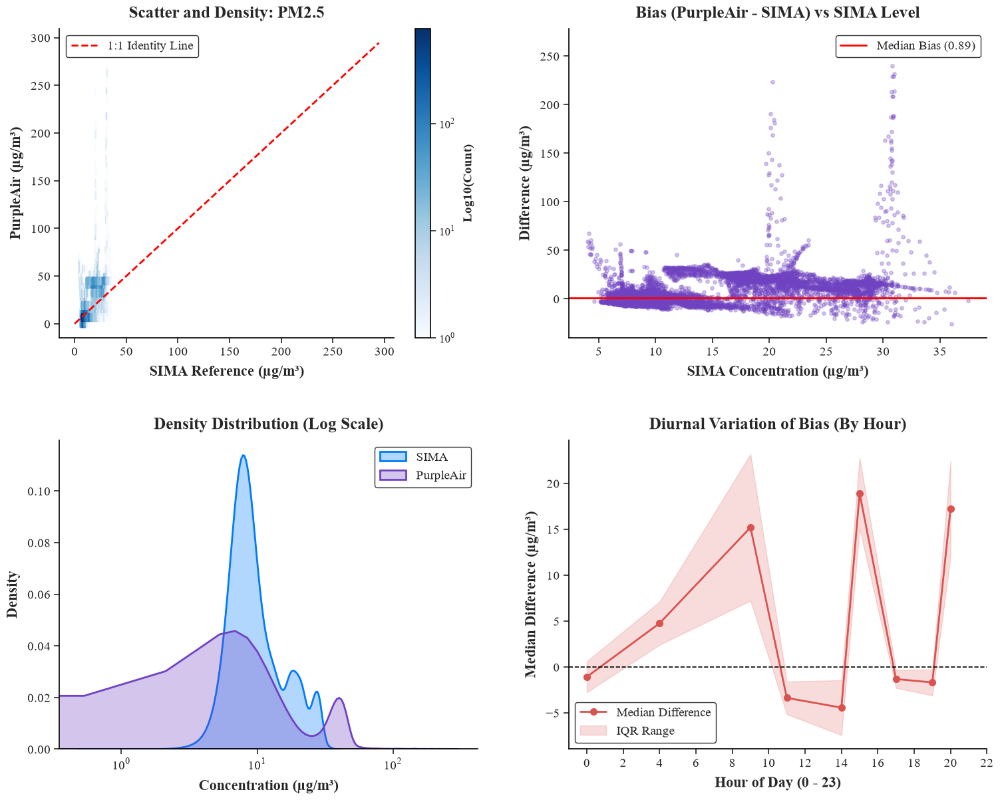


 STATISTICAL DIAGNOSTIC: PM10
Paired Records (n): 8,690
SIMA       -> Median: 42.23 µg/m³ | IQR: 22.82
PurpleAir  -> Median: 13.75 µg/m³ | IQR: 37.64
Difference -> Median Bias (PurpleAir - SIMA): -21.54 µg/m³

-- Correlation Assessment --
Pearson Correlation (Linearity): r = 0.527 (p-val: 0.00e+00)
Spearman Correlation (Monotonicity): r = 0.503 (p-val: 0.00e+00)



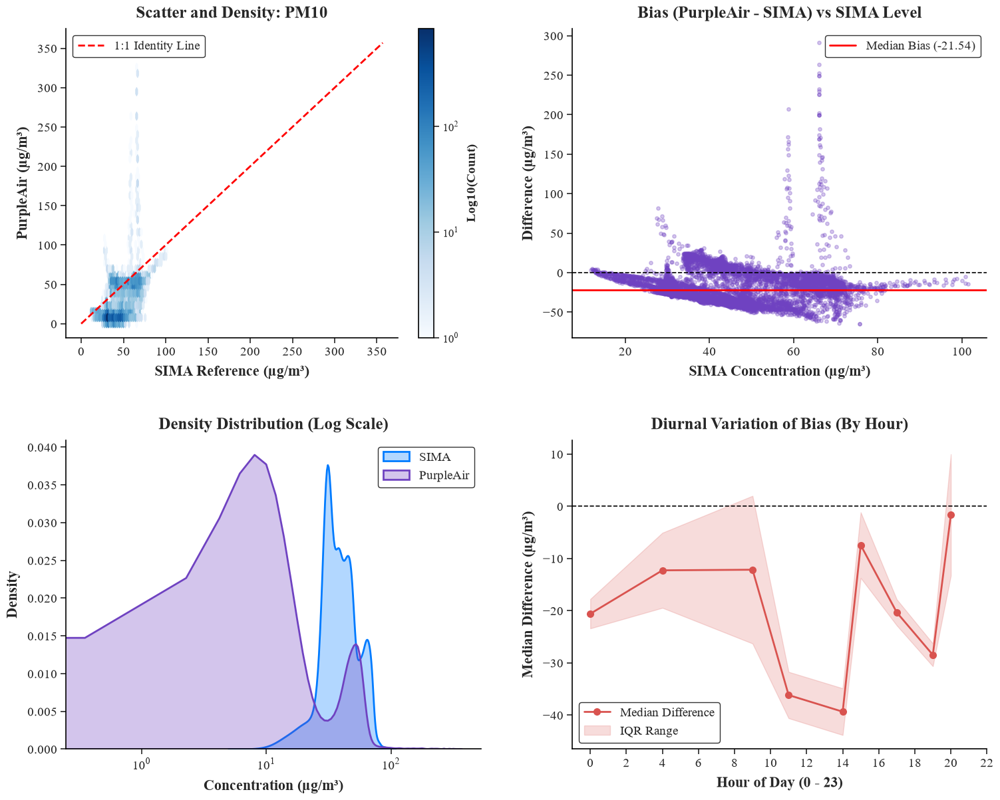

In [45]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Configure global matplotlib style for Publication Quality (Times New Roman, No Grid)
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "font.size": 14,
    "axes.labelsize": 16,
    "axes.titlesize": 18,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "figure.titlesize": 20,
    "axes.grid": False  # Remove grid background
})

COLOR_PA = "#6f42c1"
COLOR_SIMA = "#007bff"
COLOR_DIF = "#d9534f"

def plot_english_clean_eda(df_pairs):
    for cont in ["PM2.5", "PM10"]:
        sub = df_pairs[df_pairs["contaminante"] == cont].copy()
        
        # -------------------------------------------------------------------------
        # 0. Statistical Console Outputs
        # -------------------------------------------------------------------------
        med_sima = sub["SIMA"].median()
        iqr_sima = sub["SIMA"].quantile(0.75) - sub["SIMA"].quantile(0.25)
        
        med_pa = sub["PurpleAir"].median()
        iqr_pa = sub["PurpleAir"].quantile(0.75) - sub["PurpleAir"].quantile(0.25)
        
        med_dif = sub["diferencia"].median()
        
        r_pearson, p_pearson = stats.pearsonr(sub["SIMA"], sub["PurpleAir"])
        r_spearman, p_spearman = stats.spearmanr(sub["SIMA"], sub["PurpleAir"])
        
        print("\n" + "=" * 50)
        print(f" STATISTICAL DIAGNOSTIC: {cont}")
        print("=" * 50)
        print(f"Paired Records (n): {len(sub):,}")
        print(f"SIMA       -> Median: {med_sima:.2f} µg/m³ | IQR: {iqr_sima:.2f}")
        print(f"PurpleAir  -> Median: {med_pa:.2f} µg/m³ | IQR: {iqr_pa:.2f}")
        print(f"Difference -> Median Bias (PurpleAir - SIMA): {med_dif:.2f} µg/m³")
        print("\n-- Correlation Assessment --")
        print(f"Pearson Correlation (Linearity): r = {r_pearson:.3f} (p-val: {p_pearson:.2e})")
        print(f"Spearman Correlation (Monotonicity): r = {r_spearman:.3f} (p-val: {p_spearman:.2e})")
        if r_spearman - r_pearson > 0.05:
            print("💡 Note: Significant non-linear relationship or extreme outlier bias detected.")
        print("=" * 50 + "\n")
        
        # -------------------------------------------------------------------------
        # 1. Figure setup: 2x2 grid, white background
        # -------------------------------------------------------------------------
        fig, axes = plt.subplots(2, 2, figsize=(16, 13), facecolor="white")
        fig.patch.set_facecolor("white")
        
        for ax in axes.flat:
            ax.set_facecolor("white")
            for spine in ax.spines.values():
                spine.set_color("black")
                spine.set_linewidth(1.2)

        # -------------------------------------------------------------------------
        # Hexbin Scatter Plot (Top-Left)
        # -------------------------------------------------------------------------
        hb = axes[0, 0].hexbin(sub["SIMA"], sub["PurpleAir"], gridsize=40, 
                               cmap="Blues", mincnt=1, bins='log')
        max_val = max(sub["SIMA"].max(), sub["PurpleAir"].max())
        axes[0, 0].plot([0, max_val], [0, max_val], 'r--', lw=2, label="1:1 Identity Line")
        axes[0, 0].set_title(f"Scatter and Density: {cont}", fontweight="bold", pad=12)
        axes[0, 0].set_xlabel("SIMA Reference (µg/m³)")
        axes[0, 0].set_ylabel("PurpleAir (µg/m³)")
        axes[0, 0].legend(loc="upper left", frameon=True, edgecolor="black")
        
        cb = fig.colorbar(hb, ax=axes[0, 0])
        cb.set_label("Log10(Count)", fontsize=14)
        cb.ax.tick_params(labelsize=12)

        # -------------------------------------------------------------------------
        # Bias Plot / Residuals (Top-Right)
        # -------------------------------------------------------------------------
        axes[0, 1].scatter(sub["SIMA"], sub["diferencia"], alpha=0.3, color=COLOR_PA, s=15)
        axes[0, 1].axhline(0, color="black", linestyle="--", lw=1.2)
        axes[0, 1].axhline(med_dif, color="red", linestyle="-", lw=2, 
                           label=f"Median Bias ({med_dif:.2f})")
        axes[0, 1].set_title(f"Bias (PurpleAir - SIMA) vs SIMA Level", fontweight="bold", pad=12)
        axes[0, 1].set_xlabel("SIMA Concentration (µg/m³)")
        axes[0, 1].set_ylabel("Difference (µg/m³)")
        axes[0, 1].legend(loc="upper right", frameon=True, edgecolor="black")

        # -------------------------------------------------------------------------
        # Log-scale Density Distribution (Bottom-Left)
        # -------------------------------------------------------------------------
        sns.kdeplot(sub["SIMA"], ax=axes[1, 0], color=COLOR_SIMA, label="SIMA", fill=True, alpha=0.3, lw=2)
        sns.kdeplot(sub["PurpleAir"], ax=axes[1, 0], color=COLOR_PA, label="PurpleAir", fill=True, alpha=0.3, lw=2)
        axes[1, 0].set_xscale("log")
        axes[1, 0].set_title("Density Distribution (Log Scale)", fontweight="bold", pad=12)
        axes[1, 0].set_xlabel("Concentration (µg/m³)")
        axes[1, 0].set_ylabel("Density")
        axes[1, 0].legend(loc="upper right", frameon=True, edgecolor="black")

        # -------------------------------------------------------------------------
        # Diurnal Pattern of Bias (Bottom-Right)
        # -------------------------------------------------------------------------
        perfil_hora = sub.groupby("hora")["diferencia"].agg(
            ["median", lambda x: x.quantile(0.75) - x.quantile(0.25)]
        )
        perfil_hora.columns = ["mediana", "iqr"]

        axes[1, 1].plot(perfil_hora.index, perfil_hora["mediana"], marker="o", ms=7, 
                        color=COLOR_DIF, lw=2, label="Median Difference")
        axes[1, 1].fill_between(perfil_hora.index, 
                                perfil_hora["mediana"] - perfil_hora["iqr"]/2, 
                                perfil_hora["mediana"] + perfil_hora["iqr"]/2, 
                                color=COLOR_DIF, alpha=0.2, label="IQR Range")
        axes[1, 1].axhline(0, color="black", linestyle="--", lw=1.2)
        axes[1, 1].set_title("Diurnal Variation of Bias (By Hour)", fontweight="bold", pad=12)
        axes[1, 1].set_xlabel("Hour of Day (0 - 23)")
        axes[1, 1].set_ylabel("Median Difference (µg/m³)")
        axes[1, 1].set_xticks(range(0, 24, 2))
        axes[1, 1].legend(loc="lower left", frameon=True, edgecolor="black")

        plt.tight_layout(pad=3.0)
        plt.show()

# Run script
plot_english_clean_eda(df_pares)

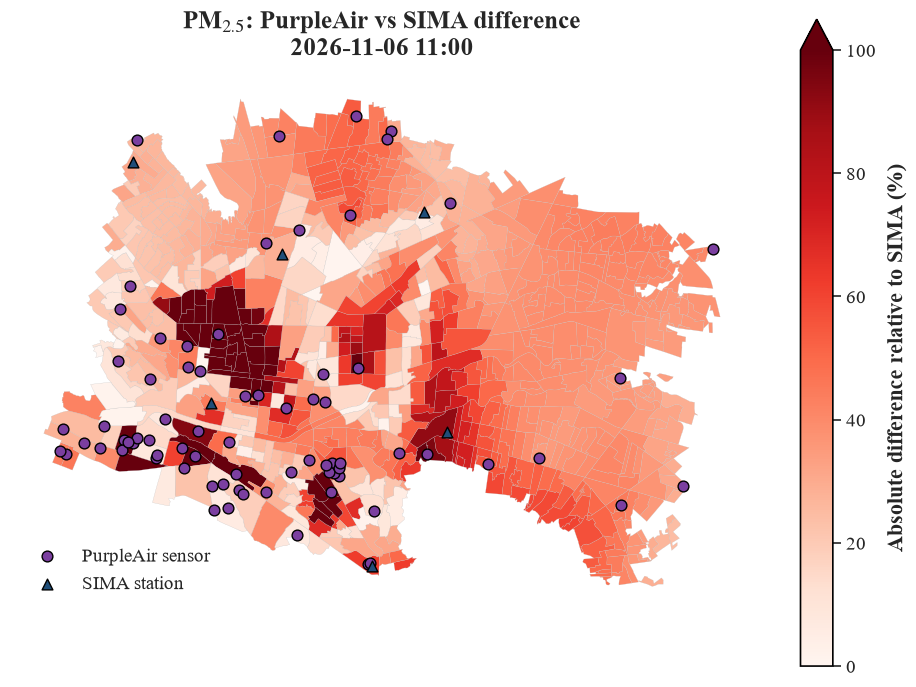

,AGEBs,%
Zona,,
Confiable (< 25 %),167,21.10
Moderada (25–50 %),441,55.80
Alta incertidumbre (≥ 50 %),182,23.00


AGEBs con mayor diferencia en el periodo:


,diferencia_pct_abs
cvegeo,
1901900010100,529.00
1901900010350,353.00
1903900010917,283.00
1903900013593,239.60
1903900010936,236.80
1903900010940,228.00
1903900010921,219.80
1903900010902,207.70
1903900012097,204.50


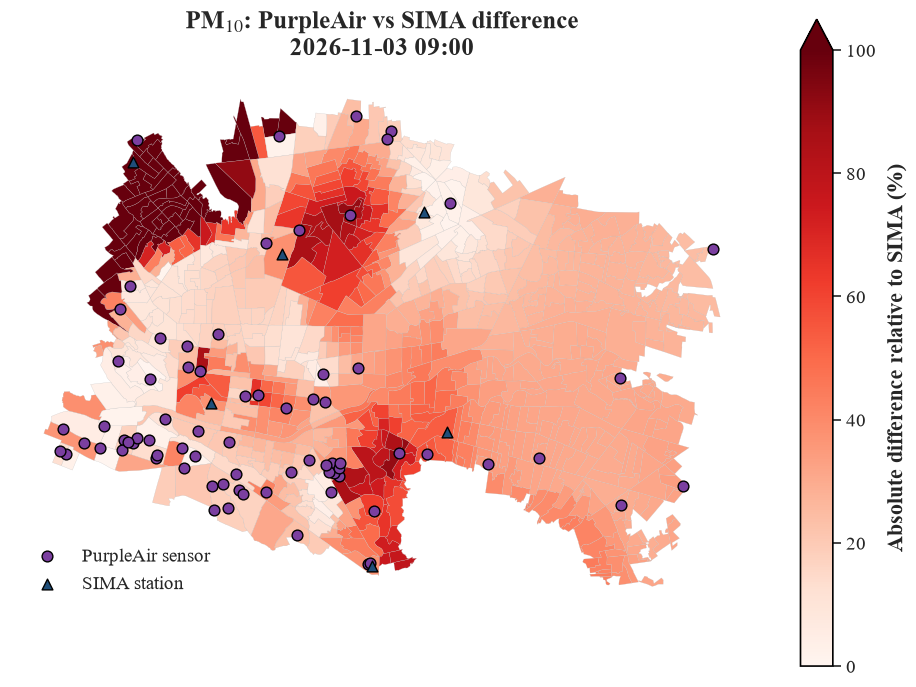

,AGEBs,%
Zona,,
Confiable (< 25 %),229,29.00
Moderada (25–50 %),416,52.70
Alta incertidumbre (≥ 50 %),145,18.40


AGEBs con mayor diferencia en el periodo:


,diferencia_pct_abs
cvegeo,
1903900012400,440.70
1903900012519,399.00
1903900012576,382.80
1903900013998,378.00
1903900013324,377.90
1903900012523,351.70
1903900010033,348.20
1903900013339,341.70
1903900014002,341.30


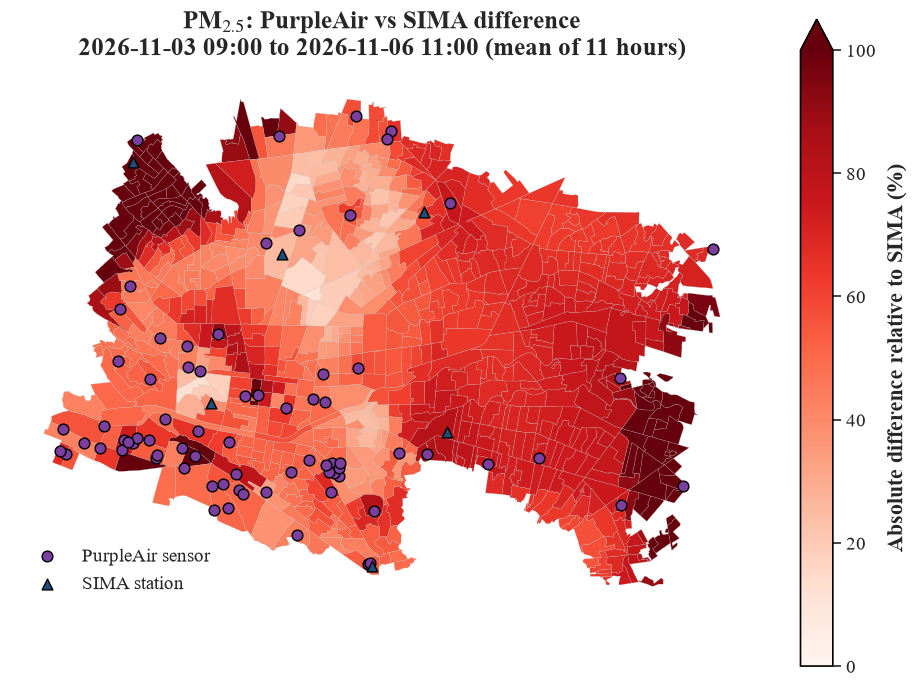

,AGEBs,%
Zona,,
Confiable (< 25 %),24,3.00
Moderada (25–50 %),193,24.40
Alta incertidumbre (≥ 50 %),573,72.50


AGEBs con mayor diferencia en el periodo:


,diferencia_pct_abs
cvegeo,
1901900010100,428.30
1903900012400,291.00
1901900010350,277.50
1903900012576,262.90
1903900012519,261.10
1903900013324,256.50
1903900013998,249.80
1903900012523,243.40
190310001068A,237.40


GIF guardado en figuras\animacion_diferencia_PM25_pct.gif


In [49]:
from matplotlib import animation
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from IPython.display import HTML

METRICA = "pct"   # "pct": |PA − SIMA| / SIMA × 100   ·   "abs": |PA − SIMA| en µg/m³
ESCALA_MAX = {"pct": 100, "abs": None}   # tope de la escala de color; None = percentil 95 de los datos
NIVELES_PCT = (25, 50)                    # % para resumir zonas: confiable < 25 ≤ moderada < 50 ≤ alta
plt.rcParams["animation.embed_limit"] = 100  # MB, para animaciones largas dentro del notebook

if agebs_gdf is None:
    raise RuntimeError("Este bloque necesita geopandas y el SHP de AGEBs (bloque 2).")

pares["diferencia_pct_abs"] = pares["diferencia_pct"].abs()
COLUMNA = {"pct": "diferencia_pct_abs", "abs": "diferencia_abs"}
ETIQUETA_METRICA = {"pct": "Absolute difference relative to SIMA (%)",
                    "abs": r"Absolute difference |PA $-$ SIMA| ($\mu$g/m$^3$)"}
MAPA_BASE = agebs_gdf.loc[agebs_gdf["cvegeo"].isin(AGEBS_COMUNES), ["cvegeo", "geometry"]].reset_index(drop=True)
ESTILO_SIN_DATO = {"color": "#EEEEEE", "edgecolor": "#BBBBBB", "linewidth": 0.15}


def tope_color(contaminante, metrica):
    if ESCALA_MAX[metrica] is not None:
        return ESCALA_MAX[metrica]
    return float(pares.loc[pares["contaminante"] == contaminante, COLUMNA[metrica]].quantile(0.95))


def diferencia_por_ageb(contaminante, inicio, fin, metrica):
    """Diferencia media de cada AGEB entre inicio y fin (inclusive)."""
    p = pares[(pares["contaminante"] == contaminante) & pares["timestamp"].between(inicio, fin)]
    return p.groupby("cvegeo")[COLUMNA[metrica]].mean(), sorted(p["timestamp"].unique())


def dibujar_mapa(ax, valores, vmax, titulo):
    ax.clear()
    MAPA_BASE.assign(valor=MAPA_BASE["cvegeo"].map(valores)).plot(
        ax=ax, column="valor", cmap="Reds", vmin=0, vmax=vmax,
        edgecolor="#BBBBBB", linewidth=0.15, missing_kwds=ESTILO_SIN_DATO)
    if not ubicaciones.empty:
        for red, marcador in (("PurpleAir", "o"), ("SIMA", "^")):
            u = ubicaciones[(ubicaciones["red"] == red) & ubicaciones["en_cobertura"]]
            ax.scatter(u["lon"], u["lat"], marker=marcador, s=60, color=COLORES[red], edgecolor="black",
                       zorder=5, label=f"{red} {'sensor' if red == 'PurpleAir' else 'station'}")
        ax.legend(loc="lower left")
    ax.set_title(titulo)
    ax.set_axis_off()


def barra_color(fig, ax, vmax, metrica):
    fig.colorbar(ScalarMappable(Normalize(0, vmax), cmap="Reds"), ax=ax, shrink=0.7,
                 label=ETIQUETA_METRICA[metrica], extend="max")


def a_fecha(valor, por_defecto):
    return pd.Timestamp(valor) if valor is not None else por_defecto


def mapa_diferencia(contaminante="PM2.5", inicio=None, fin=None, metrica=METRICA, archivo=None):
    """Mapa de la diferencia por AGEB en una hora (solo inicio) o en una ventana (inicio y fin).
    Sin fechas, usa la última hora con dato en ambas redes."""
    inicio = a_fecha(inicio, HORAS_COMUNES[-1])
    fin = a_fecha(fin, inicio)
    valores, horas = diferencia_por_ageb(contaminante, inicio, fin, metrica)
    if valores.empty:
        cercanas = sorted(HORAS_COMUNES, key=lambda h: abs(h - inicio))[:5]
        print(f"No hay lecturas emparejadas entre {inicio} y {fin}. Horas disponibles más cercanas:")
        print(", ".join(f"{h:%Y-%m-%d %H:%M}" for h in sorted(cercanas)))
        return None

    if len(horas) == 1:
        periodo = f"{horas[0]:%Y-%m-%d %H:%M}"
    else:
        periodo = f"{horas[0]:%Y-%m-%d %H:%M} to {horas[-1]:%Y-%m-%d %H:%M} (mean of {len(horas)} hours)"
    vmax = tope_color(contaminante, metrica)
    fig, ax = plt.subplots(figsize=(12, 12))
    dibujar_mapa(ax, valores, vmax, f"{ETIQUETA[contaminante]}: PurpleAir vs SIMA difference\n{periodo}")
    barra_color(fig, ax, vmax, metrica)
    if archivo:
        guardar(fig, archivo)
    plt.show()

    # Resumen de zonas por nivel de diferencia relativa
    relativa = (pares[(pares["contaminante"] == contaminante) & pares["timestamp"].between(inicio, fin)]
                .groupby("cvegeo")["diferencia_pct_abs"].mean())
    zonas = pd.cut(relativa, [-np.inf, NIVELES_PCT[0], NIVELES_PCT[1], np.inf], right=False,
                   labels=[f"Confiable (< {NIVELES_PCT[0]} %)", f"Moderada ({NIVELES_PCT[0]}–{NIVELES_PCT[1]} %)",
                           f"Alta incertidumbre (≥ {NIVELES_PCT[1]} %)"])
    resumen = zonas.value_counts(sort=False).rename_axis("Zona").to_frame("AGEBs")
    resumen["%"] = (100 * resumen["AGEBs"] / resumen["AGEBs"].sum()).round(1)
    display(resumen)
    print("AGEBs con mayor diferencia en el periodo:")
    display(valores.sort_values(ascending=False).head(10).round(1).to_frame(COLUMNA[metrica]))
    return valores


def animar_diferencia(contaminante="PM2.5", inicio=None, fin=None, metrica=METRICA,
                      ms_por_cuadro=800, guardar_gif=True):
    """Animación hora por hora de la diferencia por AGEB, con escala de color fija."""
    inicio = a_fecha(inicio, HORAS_COMUNES[0])
    fin = a_fecha(fin, HORAS_COMUNES[-1])
    p = pares[(pares["contaminante"] == contaminante) & pares["timestamp"].between(inicio, fin)]
    por_hora = {h: g.set_index("cvegeo")[COLUMNA[metrica]] for h, g in p.groupby("timestamp")}
    horas = sorted(por_hora)
    if not horas:
        print("No hay horas con dato en ambas redes en ese periodo.")
        return None

    vmax = tope_color(contaminante, metrica)
    fig, ax = plt.subplots(figsize=(12, 12))
    barra_color(fig, ax, vmax, metrica)

    def cuadro(i):
        h = horas[i]
        dibujar_mapa(ax, por_hora[h], vmax,
                     f"{ETIQUETA[contaminante]}: PurpleAir vs SIMA difference\n{h:%Y-%m-%d %H:%M} "
                     f"(frame {i + 1}/{len(horas)})")

    anim = animation.FuncAnimation(fig, cuadro, frames=len(horas), interval=ms_por_cuadro)
    if guardar_gif:
        DIR_FIGURAS.mkdir(exist_ok=True)
        ruta = DIR_FIGURAS / f"animacion_diferencia_{contaminante.replace('.', '')}_{metrica}.gif"
        anim.save(ruta, writer=animation.PillowWriter(fps=1000 / ms_por_cuadro), dpi=80)
        print(f"GIF guardado en {ruta}")
    plt.close(fig)
    return HTML(anim.to_jshtml())


# Ejemplos (cada línea en su propia celda si se prefiere):
mapa_diferencia("PM2.5")                                                      # última hora en común
mapa_diferencia("PM10", inicio="2026-11-03 09:00")                            # una hora concreta
mapa_diferencia("PM2.5", inicio=INICIO_COMUN, fin=FIN_COMUN, archivo="mapa_dif_pm25_periodo")  # todo el periodo
animar_diferencia("PM2.5")                                                    # animación de todas las horas

Geographic Coverage Alignment of SIMA and PurpleAir Data for Meteorological Parameters

In [52]:
import numpy as np
import pandas as pd
from pathlib import Path

# Geographic & Temporal Alignment for Meteorological Data
def align_meteorological_coverage(raiz_path, offset_pa=-6, offset_sima=0):
    csv_pa = raiz_path / "Purple Air" / "interpolacion_meteo_historico.csv"
    csv_sima = raiz_path / "SIMA" / "sima_interpolacion_historico.csv"

    # Read and clean SIMA Meteo
    df_sima = pd.read_csv(csv_sima, encoding="utf-8-sig", dtype={"CVEGEO": str}, na_values=["ND"], low_memory=False)
    df_sima = df_sima.rename(columns={
        "CVEGEO": "cvegeo",
        "Temperatura_C": "Temp_SIMA",
        "Humedad_pct": "RH_SIMA",
        "RadiacionSolar_Wm2": "SolarRad_SIMA"
    })
    fechas_sima = pd.to_datetime(df_sima["timestamp"], errors="coerce", utc=True, format="mixed")
    df_sima["timestamp"] = fechas_sima.dt.tz_localize(None).dt.floor("h") + pd.Timedelta(hours=offset_sima)
    df_sima["cvegeo"] = df_sima["cvegeo"].astype(str).str.strip().str.zfill(13)
    df_sima = df_sima.dropna(subset=["timestamp"]).drop_duplicates(["timestamp", "cvegeo"], keep="last")

    # Read and clean PurpleAir Meteo
    df_pa = pd.read_csv(csv_pa, encoding="utf-8-sig", dtype={"cvegeo": str}, na_values=["ND"], low_memory=False)
    df_pa = df_pa.rename(columns={
        "temperatura_interpolada_C": "Temp_PurpleAir",
        "humedad_interpolada_pct": "RH_PurpleAir"
    })
    fechas_pa = pd.to_datetime(df_pa["timestamp"], errors="coerce", utc=True, format="mixed")
    df_pa["timestamp"] = fechas_pa.dt.tz_localize(None).dt.floor("h") + pd.Timedelta(hours=offset_pa)
    df_pa["cvegeo"] = df_pa["cvegeo"].astype(str).str.strip().str.zfill(13)
    df_pa = df_pa.dropna(subset=["timestamp"]).drop_duplicates(["timestamp", "cvegeo"], keep="last")

    # Inner Join for Common Spatial and Temporal Coverage
    matched_meteo = pd.merge(
        df_pa[["timestamp", "cvegeo", "Temp_PurpleAir", "RH_PurpleAir"]],
        df_sima[["timestamp", "cvegeo", "Temp_SIMA", "RH_SIMA", "SolarRad_SIMA"]],
        on=["timestamp", "cvegeo"],
        how="inner"
    ).dropna(subset=["Temp_PurpleAir", "Temp_SIMA", "RH_PurpleAir", "RH_SIMA"])

    print(f"Total Matched Spatial-Temporal Records: {len(matched_meteo):,}")
    print(f"Common Coverage Unique AGEBs: {matched_meteo['cvegeo'].nunique()}")
    print(f"Time Horizon: {matched_meteo['timestamp'].min()} to {matched_meteo['timestamp'].max()}")

    return matched_meteo

# Run Alignment
df_meteo_pairs = align_meteorological_coverage(RAIZ)

Total Matched Spatial-Temporal Records: 25,280
Common Coverage Unique AGEBs: 790
Time Horizon: 2026-10-27 13:00:00 to 2026-11-06 11:00:00


Statistical Tests and Exploratory Analysis of Meteorological Variables


 STATISTICAL TEST DIAGNOSTIC: RELATIVE HUMIDITY
Paired Records Count (n): 25,280
SIMA Reference -> Median: 70.89 % | IQR: 24.62
PurpleAir      -> Median: 50.01 % | IQR: 22.19
Difference Bias -> Median (PA - SIMA): -16.67 %

-- Correlation Matrix --
Pearson Correlation (Linearity): r = 0.490 (p-value: 0.00e+00)
Spearman Correlation (Monotonicity): r = 0.515 (p-value: 0.00e+00)



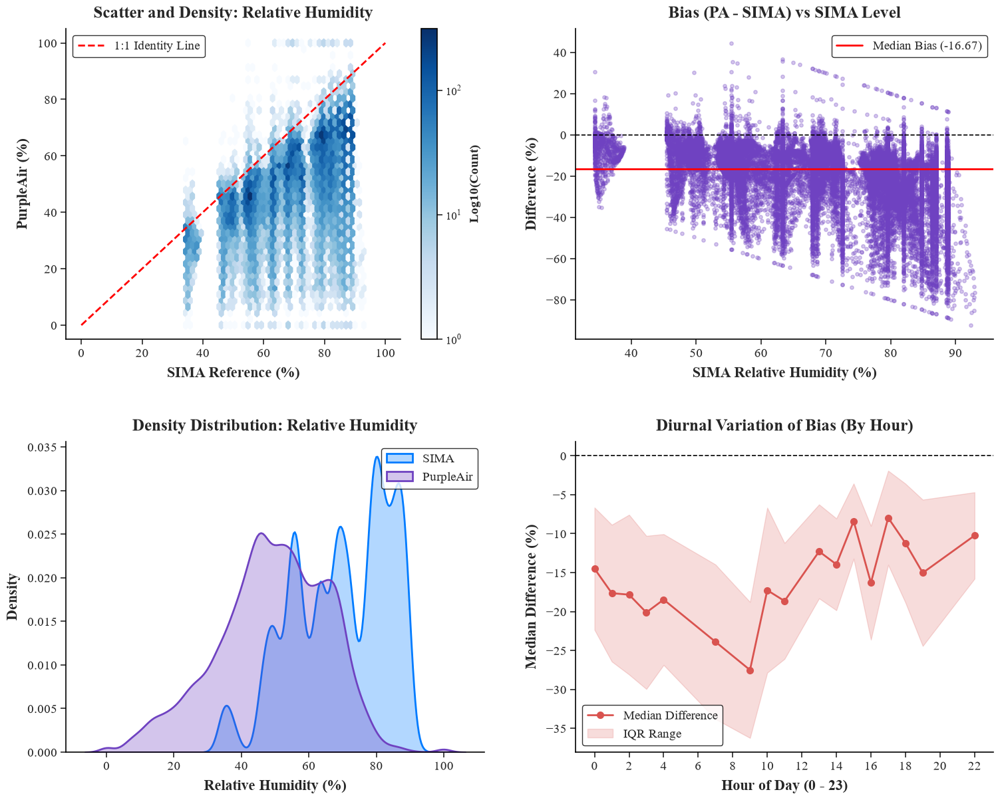


 STATISTICAL TEST DIAGNOSTIC: TEMPERATURE
Paired Records Count (n): 25,280
SIMA Reference -> Median: 23.51 °C | IQR: 3.29
PurpleAir      -> Median: 28.91 °C | IQR: 4.16
Difference Bias -> Median (PA - SIMA): 5.18 °C

-- Correlation Matrix --
Pearson Correlation (Linearity): r = 0.584 (p-value: 0.00e+00)
Spearman Correlation (Monotonicity): r = 0.598 (p-value: 0.00e+00)



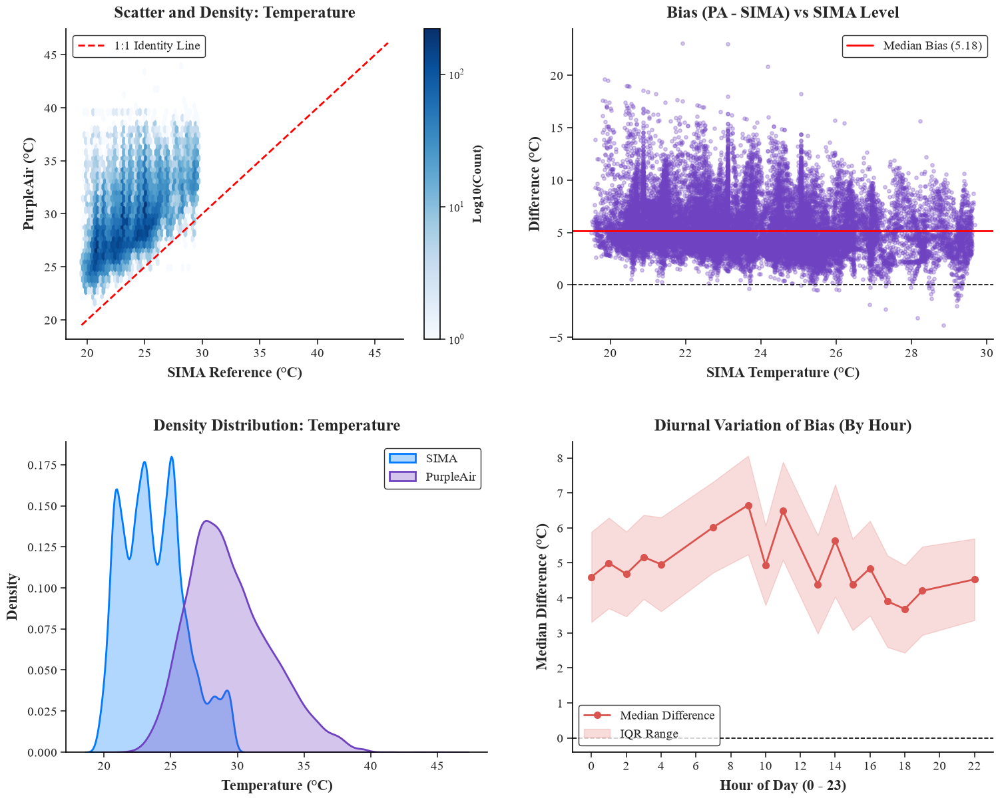

In [53]:
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Global Style Setup (Times New Roman, English, No Grid, Large Fonts)
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "font.size": 14,
    "axes.labelsize": 16,
    "axes.titlesize": 18,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "figure.titlesize": 20,
    "axes.grid": False
})

COLOR_PA = "#6f42c1"
COLOR_SIMA = "#007bff"
COLOR_DIF = "#d9534f"

def run_meteorological_statistical_tests(df_meteo):
    variables = [
        ("Relative Humidity", "RH_SIMA", "RH_PurpleAir", "%"),
        ("Temperature", "Temp_SIMA", "Temp_PurpleAir", "°C")
    ]
    
    for var_name, col_sima, col_pa, unit in variables:
        sub = df_meteo[[col_sima, col_pa, "timestamp"]].dropna().copy()
        sub["diferencia"] = sub[col_pa] - sub[col_sima]
        sub["hora"] = sub["timestamp"].dt.hour
        
        # 1. Statistical Calculations
        med_sima = sub[col_sima].median()
        iqr_sima = sub[col_sima].quantile(0.75) - sub[col_sima].quantile(0.25)
        
        med_pa = sub[col_pa].median()
        iqr_pa = sub[col_pa].quantile(0.75) - sub[col_pa].quantile(0.25)
        
        med_dif = sub["diferencia"].median()
        
        r_pearson, p_pearson = stats.pearsonr(sub[col_sima], sub[col_pa])
        r_spearman, p_spearman = stats.spearmanr(sub[col_sima], sub[col_pa])
        
        # 2. Console Summary Output
        print("\n" + "=" * 60)
        print(f" STATISTICAL TEST DIAGNOSTIC: {var_name.upper()}")
        print("=" * 60)
        print(f"Paired Records Count (n): {len(sub):,}")
        print(f"SIMA Reference -> Median: {med_sima:.2f} {unit} | IQR: {iqr_sima:.2f}")
        print(f"PurpleAir      -> Median: {med_pa:.2f} {unit} | IQR: {iqr_pa:.2f}")
        print(f"Difference Bias -> Median (PA - SIMA): {med_dif:.2f} {unit}")
        print("\n-- Correlation Matrix --")
        print(f"Pearson Correlation (Linearity): r = {r_pearson:.3f} (p-value: {p_pearson:.2e})")
        print(f"Spearman Correlation (Monotonicity): r = {r_spearman:.3f} (p-value: {p_spearman:.2e})")
        print("=" * 60 + "\n")
        
        # 3. Figure Generation (2x2 Panel)
        fig, axes = plt.subplots(2, 2, figsize=(16, 13), facecolor="white")
        fig.patch.set_facecolor("white")
        
        for ax in axes.flat:
            ax.set_facecolor("white")
            for spine in ax.spines.values():
                spine.set_color("black")
                spine.set_linewidth(1.2)
                
        # Subplot 1: Hexbin Scatter Plot
        hb = axes[0, 0].hexbin(sub[col_sima], sub[col_pa], gridsize=40, cmap="Blues", mincnt=1, bins='log')
        max_val = max(sub[col_sima].max(), sub[col_pa].max())
        min_val = min(sub[col_sima].min(), sub[col_pa].min())
        axes[0, 0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label="1:1 Identity Line")
        axes[0, 0].set_title(f"Scatter and Density: {var_name}", fontweight="bold", pad=12)
        axes[0, 0].set_xlabel(f"SIMA Reference ({unit})")
        axes[0, 0].set_ylabel(f"PurpleAir ({unit})")
        axes[0, 0].legend(loc="upper left", frameon=True, edgecolor="black")
        
        cb = fig.colorbar(hb, ax=axes[0, 0])
        cb.set_label("Log10(Count)", fontsize=14)
        cb.ax.tick_params(labelsize=12)
        
        # Subplot 2: Bias Plot (Residuals)
        axes[0, 1].scatter(sub[col_sima], sub["diferencia"], alpha=0.3, color=COLOR_PA, s=15)
        axes[0, 1].axhline(0, color="black", linestyle="--", lw=1.2)
        axes[0, 1].axhline(med_dif, color="red", linestyle="-", lw=2, label=f"Median Bias ({med_dif:.2f})")
        axes[0, 1].set_title(f"Bias (PA - SIMA) vs SIMA Level", fontweight="bold", pad=12)
        axes[0, 1].set_xlabel(f"SIMA {var_name} ({unit})")
        axes[0, 1].set_ylabel(f"Difference ({unit})")
        axes[0, 1].legend(loc="upper right", frameon=True, edgecolor="black")
        
        # Subplot 3: KDE Density Distribution
        sns.kdeplot(sub[col_sima], ax=axes[1, 0], color=COLOR_SIMA, label="SIMA", fill=True, alpha=0.3, lw=2)
        sns.kdeplot(sub[col_pa], ax=axes[1, 0], color=COLOR_PA, label="PurpleAir", fill=True, alpha=0.3, lw=2)
        axes[1, 0].set_title(f"Density Distribution: {var_name}", fontweight="bold", pad=12)
        axes[1, 0].set_xlabel(f"{var_name} ({unit})")
        axes[1, 0].set_ylabel("Density")
        axes[1, 0].legend(loc="upper right", frameon=True, edgecolor="black")
        
        # Subplot 4: Diurnal Variation of Bias
        perfil_hora = sub.groupby("hora")["diferencia"].agg(["median", lambda x: x.quantile(0.75) - x.quantile(0.25)])
        perfil_hora.columns = ["mediana", "iqr"]
        
        axes[1, 1].plot(perfil_hora.index, perfil_hora["mediana"], marker="o", ms=7, color=COLOR_DIF, lw=2, label="Median Difference")
        axes[1, 1].fill_between(perfil_hora.index, perfil_hora["mediana"] - perfil_hora["iqr"]/2, 
                                perfil_hora["mediana"] + perfil_hora["iqr"]/2, color=COLOR_DIF, alpha=0.2, label="IQR Range")
        axes[1, 1].axhline(0, color="black", linestyle="--", lw=1.2)
        axes[1, 1].set_title("Diurnal Variation of Bias (By Hour)", fontweight="bold", pad=12)
        axes[1, 1].set_xlabel("Hour of Day (0 - 23)")
        axes[1, 1].set_ylabel(f"Median Difference ({unit})")
        axes[1, 1].set_xticks(range(0, 24, 2))
        axes[1, 1].legend(loc="lower left", frameon=True, edgecolor="black")
        
        plt.tight_layout(pad=3.0)
        plt.show()

# Run Statistical Test Suite
run_meteorological_statistical_tests(df_meteo_pairs)